# Predicting Term-Deposit Subscription from Bank Telemarketing Data

**Udacity / Woolf Master's in AI – Capstone Project 3: Applied Machine Learning: Model Design, Training, and Performance Evaluation**

## 0. Problem Statement

A Portuguese bank ran phone-based marketing campaigns to sell a term deposit. Calling every client is expensive, and most clients say no. The goal of this notebook is to build a model that, **before a call is made**, estimates how likely a client is to subscribe, so the bank can prioritise its call list.

- **Problem type:** Supervised learning – binary classification (target `y`: subscribed to a term deposit, `yes` / `no`).
- **Dataset:** Bank Marketing (`bank-full.csv`, 45,211 rows, 16 input features + target), UCI Machine Learning Repository – <https://archive.ics.uci.edu/dataset/222/bank+marketing> (DOI: <https://doi.org/10.24432/C5K306>), licensed CC BY 4.0. Citation: Moro, S., Rita, P., & Cortez, P. (2014). *Bank marketing* [Dataset]. UCI Machine Learning Repository.
- **Not used in earlier projects:** Project 1 used Titanic and Project 2 used Medical Cost (insurance).

**Workflow:** load and inspect → identify data-quality issues and leakage → stratified split → `Pipeline` + `ColumnTransformer` preprocessing → baselines (majority-class dummy, logistic regression) and a main model (random forest tuned with cross-validation) → test-set evaluation, threshold tuning, feature importance, a time-ordered robustness check and an age-group bias check → `metrics.json` for the report.

## 1. Imports and Configuration

All randomness is fixed with `random_state=42`. Every figure is saved to `figures/` as PNG.

In [1]:
import json
import platform
import time
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from matplotlib.colors import LinearSegmentedColormap
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import UndefinedMetricWarning
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report, confusion_matrix,
    f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# --- Reproducibility and paths ---
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
DATA_PATH = Path("bank-full.csv")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
METRICS_PATH = Path("metrics.json")
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# --- Plot style: neutral ink, recessive grid, one fixed colour per model in every figure ---
INK, INK_MUTED, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"
MODEL_COLORS = {
    "Random forest": "#2a78d6",
    "Logistic regression": "#eb6834",
    "Dummy (majority class)": "#1baf7a",
}
BLUE_CMAP = LinearSegmentedColormap.from_list("blue_seq", ["#f4f8fe", "#86b6ef", "#2a78d6", "#104281"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": INK_MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False, "figure.dpi": 110,
})


def save_fig(fig, name):
    """Save a figure to figures/<name>.png at 200 dpi and return the path."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    return path


print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__} | seaborn {sns.__version__}")

Python 3.11.0 | numpy 2.4.6 | pandas 3.1.0 | scikit-learn 1.9.1 | matplotlib 3.11.2 | seaborn 0.13.2


## 2. Load and Inspect the Data

The UCI file is semicolon-separated, so it is read with `sep=";"`.

In [2]:
df = pd.read_csv(DATA_PATH, sep=";")
print("Shape (rows, columns):", df.shape)
print("Columns:", list(df.columns))
df.head()

Shape (rows, columns): (45211, 17)
Columns: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.94,10.62,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.27,3044.77,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.81,8.32,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.16,257.53,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.76,3.10,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.20,100.13,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.58,2.30,0.0,0.0,0.0,0.0,275.0


In [5]:
# Missing values, duplicates and "unknown" placeholders
missing = df.isna().sum()
n_duplicates = int(df.duplicated().sum())
print("Total missing (NaN) values:", int(missing.sum()))
print("Duplicate rows:", n_duplicates)

cat_raw = df.select_dtypes(exclude="number").columns
unknown_pct = (df[cat_raw] == "unknown").mean().mul(100).round(2)
unknown_pct = unknown_pct[unknown_pct > 0].sort_values(ascending=False)
pdays_never_pct = round((df["pdays"] == -1).mean() * 100, 2)
print(f"\nClients never contacted before (pdays == -1): {pdays_never_pct}%")
print("\nShare of 'unknown' placeholders per column (%):")
unknown_pct.to_frame("unknown_%")

Total missing (NaN) values: 0
Duplicate rows: 0

Clients never contacted before (pdays == -1): 81.74%

Share of 'unknown' placeholders per column (%):


,unknown_%
poutcome,81.75
contact,28.80
education,4.11
job,0.64


     count  percent
y                  
no   39922     88.3
yes   5289     11.7


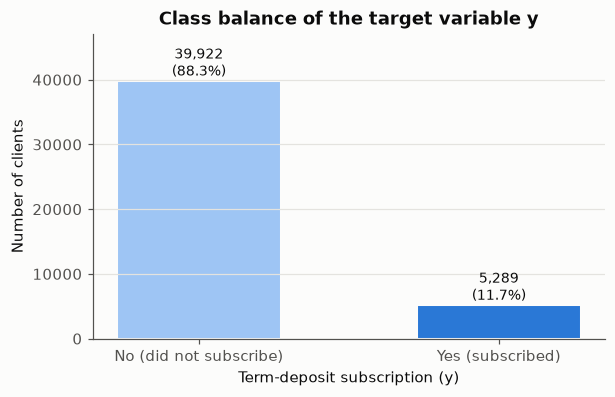

In [6]:
# Target distribution (class balance)
target_counts = df["y"].value_counts()
target_pct = df["y"].value_counts(normalize=True).mul(100).round(2)
print(pd.DataFrame({"count": target_counts, "percent": target_pct}))

fig, ax = plt.subplots(figsize=(6, 3.6))
bars = ax.bar(["No (did not subscribe)", "Yes (subscribed)"], target_counts[["no", "yes"]],
              color=["#9ec5f4", "#2a78d6"], width=0.55, edgecolor=SURFACE, linewidth=2)
for bar, pct in zip(bars, target_pct[["no", "yes"]]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{bar.get_height():,.0f}\n({pct:.1f}%)",
            ha="center", va="bottom", color=INK, fontsize=9)
ax.set_title("Class balance of the target variable y")
ax.set_xlabel("Term-deposit subscription (y)")
ax.set_ylabel("Number of clients")
ax.set_ylim(0, target_counts.max() * 1.18)
ax.grid(axis="x", visible=False)
save_fig(fig, "01_class_balance")
plt.show()

### Data-quality issues found

1. **No NaNs and no duplicate rows, but there are hidden missing values.** The text `"unknown"` is a placeholder in `poutcome` (81.75%), `contact` (28.80%), `education` (4.11%) and `job` (0.64%). It is kept as its own category because "no recorded value" is itself informative here.
2. **Sentinel value in `pdays`.** `-1` means "never contacted before" (81.74% of clients). It is not a real number of days, so a binary flag `previously_contacted` is added next to it.
3. **Class imbalance.** Only 5,289 of 45,211 clients (11.7%) subscribed, against 39,922 (88.3%) who did not. A model that always answers "no" is already 88.3% accurate, so accuracy alone is misleading.
4. **Target leakage: `duration`.** Call length is recorded only after the call ends, when the outcome is already known, so it is dropped (Moro et al., 2014).
5. **Skewed numeric features with extreme values.** `balance` ranges from -8,019 to 102,127 euros, `campaign` reaches 63 calls and `previous` reaches 275. They are kept, because they are plausible values rather than errors. Trees are insensitive to them, and standardisation keeps them from dominating the logistic regression.
6. **Rows are ordered in time** (May 2008 to November 2010). A random split ignores this, so a time-ordered check is run in Section 5.

## 3. Preprocessing

Steps, in this order:

1. **Drop the leakage column `duration`.** The dataset documentation says call duration strongly drives the target but is only known *after* the call, so it should be discarded for a realistic predictive model (Moro et al., 2014).
2. **Add one row-wise feature, `previously_contacted`** (1 if `pdays != -1`). This only reads the client's own row, so it uses no information from other rows and cannot leak test data.
3. **Stratified train/test split (80/20)** *before* fitting any transformer, so the test set keeps the real 11.7% positive rate and plays no part in any fitted statistic.
4. **`Pipeline` + `ColumnTransformer`:** numeric columns get median imputation and standardisation, and categorical columns get most-frequent imputation and one-hot encoding (`handle_unknown="ignore"`). Fitting the preprocessing inside a pipeline means it learns only from training data, including inside every cross-validation fold, which is the recommended guard against data leakage (scikit-learn developers, 2026).

**Why these choices fit the models.** One-hot encoding lets both logistic regression and the random forest use nominal categories without implying an order. Scaling matters for logistic regression, whose regularised coefficients depend on feature scale. It does not change a tree's splits, so one shared preprocessor serves both models fairly. The `"unknown"` labels are kept as their own category rather than imputed, because "no recorded previous outcome" carries information in itself. The imputers are a safety net: the file has no NaNs today, but a future extract might.

In [7]:
LEAKAGE_COLS = ["duration"]   # known only after the call -> leaks the outcome
TARGET = "y"

df_model = df.drop(columns=LEAKAGE_COLS).copy()
df_model["previously_contacted"] = (df_model["pdays"] != -1).astype(int)

y = (df_model.pop(TARGET) == "yes").astype(int)
X = df_model
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print(f"Numeric features ({len(num_cols)}):", num_cols)
print(f"Categorical features ({len(cat_cols)}):", cat_cols)

# Stratified split BEFORE fitting any transformer
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"\nTrain: {X_train.shape}, positive rate {y_train.mean():.4f}")
print(f"Test:  {X_test.shape}, positive rate {y_test.mean():.4f}")

Numeric features (7): ['age', 'balance', 'day', 'campaign', 'pdays', 'previous', 'previously_contacted']
Categorical features (9): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Train: (36168, 16), positive rate 0.1170
Test:  (9043, 16), positive rate 0.1170


In [8]:
def make_preprocessor():
    """Return an unfitted ColumnTransformer: impute + scale numerics, impute + one-hot categoricals."""
    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    categorical = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([("num", numeric, num_cols), ("cat", categorical, cat_cols)])


# Show what the preprocessor produces (fitted on training data only)
pre_check = make_preprocessor().fit(X_train)
encoded_names = pre_check.get_feature_names_out()
print("Encoded feature matrix width:", len(encoded_names))
print(encoded_names[:12], "...")

Encoded feature matrix width: 51
['num__age' 'num__balance' 'num__day' 'num__campaign' 'num__pdays'
 'num__previous' 'num__previously_contacted' 'cat__job_admin.'
 'cat__job_blue-collar' 'cat__job_entrepreneur' 'cat__job_housemaid'
 'cat__job_management'] ...


## 4. Model Training

Three models share the same preprocessing pipeline:

| Role | Model | Why |
|---|---|---|
| Naive baseline | `DummyClassifier(strategy="most_frequent")` | Always predicts "no". It shows what accuracy is worth on imbalanced data. |
| Simple baseline | `LogisticRegression(class_weight="balanced")` | A linear, interpretable reference. |
| **Main model** | `RandomForestClassifier(class_weight="balanced_subsample")` | Captures non-linear effects and interactions (for example month × previous outcome) without manual feature engineering. |

Because only about 1 client in 9 subscribes, both real models re-weight the classes so the minority class is not ignored. The random forest is tuned with a small `GridSearchCV` (5-fold stratified CV) scored on **average precision (PR-AUC)**, the metric that matches the business goal of ranking likely subscribers.

In [9]:
# Baselines: 5-fold cross-validation on the training set (mean ± std)
SCORING = {"pr_auc": "average_precision", "roc_auc": "roc_auc", "recall": "recall",
           "precision": "precision", "f1": "f1"}

baselines = {
    "Dummy (majority class)": Pipeline([("prep", make_preprocessor()),
                                        ("model", DummyClassifier(strategy="most_frequent"))]),
    "Logistic regression": Pipeline([("prep", make_preprocessor()),
                                     ("model", LogisticRegression(class_weight="balanced", max_iter=2000,
                                                                  random_state=RANDOM_STATE))]),
}

cv_summary = {}
for name, pipe in baselines.items():
    start = time.perf_counter()
    with warnings.catch_warnings():
        # The dummy never predicts "yes", so its precision is undefined (reported as 0) - expected.
        warnings.simplefilter("ignore", UndefinedMetricWarning)
        scores = cross_validate(pipe, X_train, y_train, cv=CV, scoring=SCORING, error_score="raise")
    cv_summary[name] = {m: (scores[f"test_{m}"].mean(), scores[f"test_{m}"].std()) for m in SCORING}
    pipe.fit(X_train, y_train)          # final fit on the full training set
    print(f"{name}: trained in {time.perf_counter() - start:.1f}s")

Dummy (majority class): trained in 0.5s


Logistic regression: trained in 1.5s


In [10]:
# Main model: random forest + small grid search (5-fold stratified CV, scored on PR-AUC)
rf_pipe = Pipeline([
    ("prep", make_preprocessor()),
    ("model", RandomForestClassifier(n_estimators=300, max_features="sqrt",
                                     class_weight="balanced_subsample",
                                     n_jobs=-1, random_state=RANDOM_STATE)),
])
param_grid = {
    "model__max_depth": [12, None],
    "model__min_samples_leaf": [5, 20],
}
grid = GridSearchCV(rf_pipe, param_grid, cv=CV, scoring=SCORING, refit="pr_auc",
                    return_train_score=True, n_jobs=1)

start = time.perf_counter()
grid.fit(X_train, y_train)
print(f"Grid search ({len(grid.cv_results_['params'])} settings x 5 folds) finished in "
      f"{time.perf_counter() - start:.0f}s")
print("Best parameters:", grid.best_params_)

cv_table = pd.DataFrame(grid.cv_results_)[[
    "param_model__max_depth", "param_model__min_samples_leaf",
    "mean_train_pr_auc", "mean_test_pr_auc", "std_test_pr_auc", "mean_test_recall", "mean_test_precision",
]].rename(columns=lambda c: c.replace("param_model__", "")).sort_values("mean_test_pr_auc", ascending=False)
cv_table.round(4)

Grid search (4 settings x 5 folds) finished in 34s
Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 5}


,max_depth,min_samples_leaf,mean_train_pr_auc,mean_test_pr_auc,std_test_pr_auc,mean_test_recall,mean_test_precision
2,None,5,0.7221,0.4411,0.0174,0.5167,0.4343
0,12,5,0.5649,0.4365,0.0149,0.5814,0.3664
3,None,20,0.5311,0.4344,0.0125,0.5843,0.3603
1,12,20,0.4966,0.4312,0.0122,0.5968,0.3371


In [11]:
best_rf = grid.best_estimator_
bi = grid.best_index_
cv_summary["Random forest"] = {m: (grid.cv_results_[f"mean_test_{m}"][bi], grid.cv_results_[f"std_test_{m}"][bi])
                               for m in SCORING}

cv_df = pd.DataFrame({name: {m: f"{mu:.3f} ± {sd:.3f}" for m, (mu, sd) in res.items()}
                      for name, res in cv_summary.items()}).T
cv_df.columns = ["PR-AUC", "ROC-AUC", "Recall", "Precision", "F1"]
print("5-fold cross-validation on the TRAINING set (mean ± std, threshold 0.5)")
cv_df

5-fold cross-validation on the TRAINING set (mean ± std, threshold 0.5)


,PR-AUC,ROC-AUC,Recall,Precision,F1
Dummy (majority class),0.117 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
Logistic regression,0.398 ± 0.007,0.764 ± 0.003,0.623 ± 0.010,0.266 ± 0.004,0.373 ± 0.003
Random forest,0.441 ± 0.017,0.793 ± 0.004,0.517 ± 0.021,0.434 ± 0.003,0.472 ± 0.009


### Cross-validation results

The best random forest setting (`max_depth=None`, `min_samples_leaf=5`) reached a cross-validated PR-AUC of **0.441 ± 0.017**, against 0.398 ± 0.007 for logistic regression and 0.117 for the dummy. The dummy's 0.117 equals the share of subscribers, which is what a random ranking scores. The fold-to-fold standard deviations are small compared with the gap between the models, so the forest's advantage is not fold noise. At the default 0.5 threshold, logistic regression has the higher recall (0.623 vs 0.517) but much lower precision (0.266 vs 0.434): balanced class weights push many clients above 0.5, so it flags far more people. The four forest settings differ by only 0.010 in CV PR-AUC (0.431 to 0.441), so the result is not sensitive to these hyperparameters.

### Choosing a decision threshold (on training data only)

A probability threshold of 0.5 is arbitrary, and class weighting shifts the forest's probabilities upward. To choose an operating point **without touching the test set**, out-of-fold probabilities are produced on the training set with 5-fold CV. The threshold that maximises F1 on those out-of-fold predictions is then frozen and applied once to the test set.

In [12]:
oof_proba = cross_val_predict(clone(best_rf), X_train, y_train, cv=CV, method="predict_proba")[:, 1]
prec_oof, rec_oof, thr_oof = precision_recall_curve(y_train, oof_proba)
f1_oof = 2 * prec_oof[:-1] * rec_oof[:-1] / np.clip(prec_oof[:-1] + rec_oof[:-1], 1e-12, None)
best_t_idx = int(np.argmax(f1_oof))
THRESHOLD = float(thr_oof[best_t_idx])
print(f"Chosen threshold (max out-of-fold F1): {THRESHOLD:.3f}")
print(f"Out-of-fold at this threshold: precision {prec_oof[best_t_idx]:.3f}, recall {rec_oof[best_t_idx]:.3f}, "
      f"F1 {f1_oof[best_t_idx]:.3f}")

Chosen threshold (max out-of-fold F1): 0.487
Out-of-fold at this threshold: precision 0.429, recall 0.533, F1 0.476


## 5. Evaluation on the Held-Out Test Set

The test set (9,043 clients) was not used for any fitting, tuning or threshold choice. Accuracy is reported, but because 88.3% of clients are "no", it is a weak signal on its own. The focus is on **precision** (of the clients we flag, how many subscribe), **recall** (of the real subscribers, how many we flag), **F1**, **ROC-AUC** and especially **PR-AUC**, which is more informative than ROC when positives are rare (Saito & Rehmsmeier, 2015).

In [13]:
def evaluate(y_true, proba, threshold=0.5):
    """Return threshold-based and ranking metrics for one model's positive-class probabilities."""
    pred = (proba >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred),
        "f1": f1_score(y_true, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, proba),
        "pr_auc": average_precision_score(y_true, proba),
        "threshold": threshold,
    }


test_proba = {name: pipe.predict_proba(X_test)[:, 1] for name, pipe in baselines.items()}
test_proba["Random forest"] = best_rf.predict_proba(X_test)[:, 1]

results = {
    "Dummy (majority class)": evaluate(y_test, test_proba["Dummy (majority class)"]),
    "Logistic regression": evaluate(y_test, test_proba["Logistic regression"]),
    "Random forest (t = 0.50)": evaluate(y_test, test_proba["Random forest"]),
    f"Random forest (tuned t = {THRESHOLD:.2f})": evaluate(y_test, test_proba["Random forest"], THRESHOLD),
}
metrics_table = pd.DataFrame(results).T[["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "threshold"]]
metrics_table.columns = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC", "Threshold"]
print(f"Test-set prevalence (PR-AUC of a random ranking): {y_test.mean():.3f}")
metrics_table.round(3)

Test-set prevalence (PR-AUC of a random ranking): 0.117


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Threshold
Dummy (majority class),0.883,0.000,0.000,0.000,0.500,0.117,0.500
Logistic regression,0.755,0.267,0.624,0.374,0.772,0.409,0.500
Random forest (t = 0.50),0.866,0.440,0.534,0.483,0.804,0.454,0.500
Random forest (tuned t = 0.49),0.863,0.432,0.553,0.485,0.804,0.454,0.487


### Metrics comparison

- The **dummy** scores the highest accuracy (0.883) while finding **zero** subscribers, which shows directly why accuracy is the wrong headline metric here.
- **Logistic regression** has lower accuracy (0.755) but finds 62.4% of subscribers. Only 26.7% of the clients it flags actually subscribe.
- The **random forest** at the tuned threshold reaches precision **0.432**, recall **0.553**, F1 **0.485**, ROC-AUC **0.804** and PR-AUC **0.454**. That PR-AUC is about 3.9 times the 0.117 a random call list would achieve.
- The test PR-AUC (0.454) is close to the cross-validated value (0.441), so the held-out estimate is stable.
- The F1-optimal threshold found on training data (0.487) is almost the default 0.5, so threshold tuning changed little: recall rose by 0.019 and precision fell by 0.008. Class weighting had already placed the balanced operating point near 0.5.

In [14]:
rf_pred_tuned = (test_proba["Random forest"] >= THRESHOLD).astype(int)
rf_pred_default = (test_proba["Random forest"] >= 0.5).astype(int)
print(f"Classification report – random forest, tuned threshold {THRESHOLD:.2f}")
print(classification_report(y_test, rf_pred_tuned, target_names=["no", "yes"], digits=3))
print("Classification report – random forest, threshold 0.50")
print(classification_report(y_test, rf_pred_default, target_names=["no", "yes"], digits=3))

Classification report – random forest, tuned threshold 0.49
              precision    recall  f1-score   support

          no      0.938     0.904     0.921      7985
         yes      0.432     0.553     0.485      1058

    accuracy                          0.863      9043
   macro avg      0.685     0.728     0.703      9043
weighted avg      0.879     0.863     0.870      9043

Classification report – random forest, threshold 0.50
              precision    recall  f1-score   support

          no      0.936     0.910     0.923      7985
         yes      0.440     0.534     0.483      1058

    accuracy                          0.866      9043
   macro avg      0.688     0.722     0.703      9043
weighted avg      0.878     0.866     0.872      9043



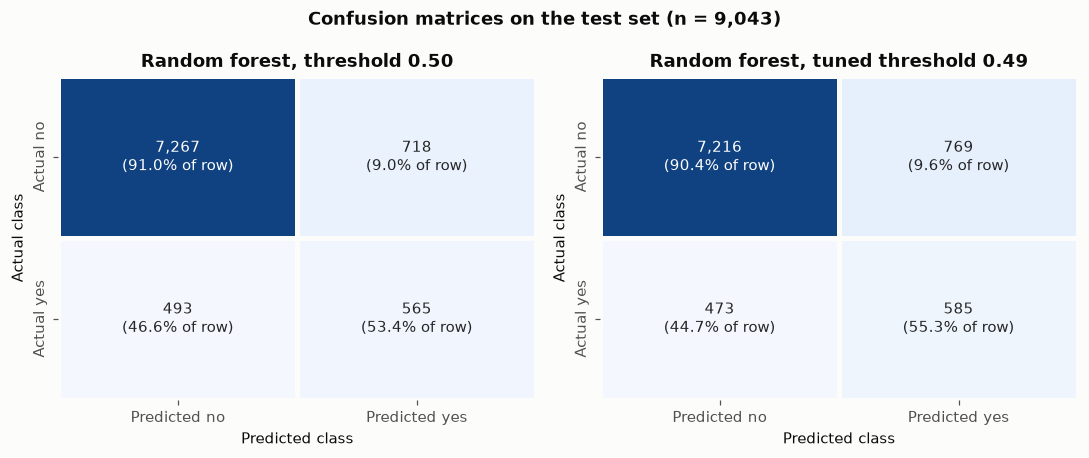

In [15]:
# Confusion matrices: default vs tuned threshold
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
cms = {}
for ax, (label, pred) in zip(axes, [("threshold 0.50", rf_pred_default), (f"tuned threshold {THRESHOLD:.2f}", rf_pred_tuned)]):
    cm = confusion_matrix(y_test, pred)
    cms[label] = cm
    row_pct = cm / cm.sum(axis=1, keepdims=True) * 100
    annot = np.array([[f"{cm[i, j]:,}\n({row_pct[i, j]:.1f}% of row)" for j in range(2)] for i in range(2)])
    sns.heatmap(cm, annot=annot, fmt="", cmap=BLUE_CMAP, cbar=False, ax=ax, linewidths=2, linecolor=SURFACE,
                xticklabels=["Predicted no", "Predicted yes"], yticklabels=["Actual no", "Actual yes"],
                annot_kws={"fontsize": 10})
    ax.set_title(f"Random forest, {label}")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
    ax.grid(False)
fig.suptitle("Confusion matrices on the test set (n = 9,043)", fontweight="bold")
fig.tight_layout()
save_fig(fig, "02_confusion_matrix")
plt.show()

### Confusion matrix

At the tuned threshold the forest flags 1,354 of the 9,043 test clients (769 + 585, about 15%), and 585 of them really subscribe. It misses 473 of the 1,058 subscribers (44.7%) and wrongly flags 769 of the 7,985 non-subscribers (9.6%). Lowering the threshold from 0.50 to 0.49 found 20 more subscribers (565 → 585) at the cost of 51 extra unnecessary calls (718 → 769). That is the precision–recall trade-off in concrete numbers. Which side matters more is a business decision: a missed subscriber is lost revenue, while a false alarm is one wasted call.

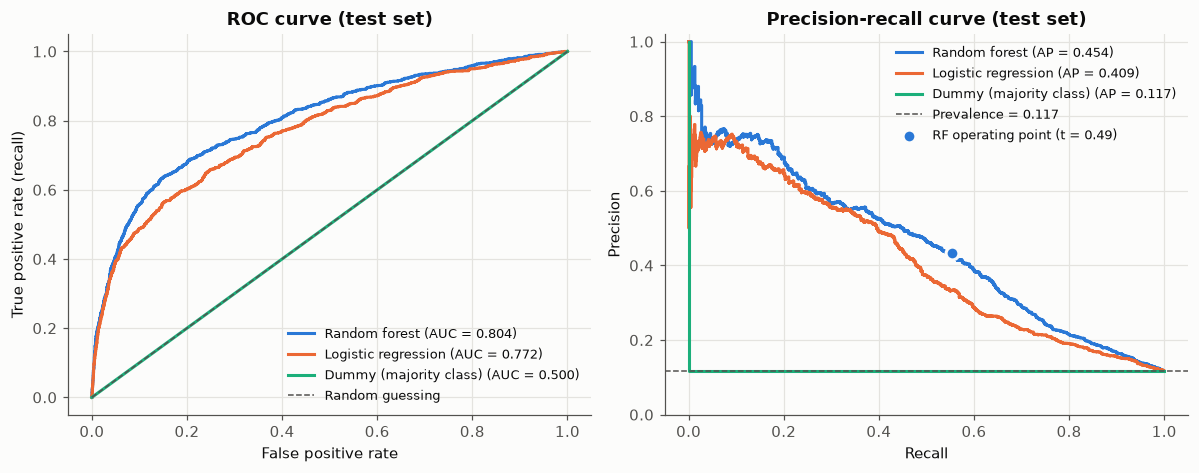

In [16]:
# ROC and precision-recall curves for all three models
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for name in ["Random forest", "Logistic regression", "Dummy (majority class)"]:
    fpr, tpr, _ = roc_curve(y_test, test_proba[name])
    axes[0].plot(fpr, tpr, color=MODEL_COLORS[name], label=f"{name} (AUC = {roc_auc_score(y_test, test_proba[name]):.3f})")
    p, r, _ = precision_recall_curve(y_test, test_proba[name])
    axes[1].plot(r, p, color=MODEL_COLORS[name], drawstyle="steps-post",
                 label=f"{name} (AP = {average_precision_score(y_test, test_proba[name]):.3f})")
axes[0].plot([0, 1], [0, 1], ls="--", lw=1, color=INK_MUTED, label="Random guessing")
axes[0].set(title="ROC curve (test set)", xlabel="False positive rate", ylabel="True positive rate (recall)")
axes[1].axhline(y_test.mean(), ls="--", lw=1, color=INK_MUTED, label=f"Prevalence = {y_test.mean():.3f}")
tuned = results[f"Random forest (tuned t = {THRESHOLD:.2f})"]
axes[1].scatter(tuned["recall"], tuned["precision"], s=70, color=MODEL_COLORS["Random forest"],
                edgecolor=SURFACE, linewidth=2, zorder=5, label=f"RF operating point (t = {THRESHOLD:.2f})")
axes[1].set(title="Precision-recall curve (test set)", xlabel="Recall", ylabel="Precision", ylim=(0, 1.02))
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "upper right", fontsize=8.5)
fig.tight_layout()
save_fig(fig, "03_roc_pr_curves")
plt.show()

### ROC and precision-recall curves

The random forest's curves lie above logistic regression's almost everywhere (ROC-AUC 0.804 vs 0.772, PR-AUC 0.454 vs 0.409). The PR curve shows the gap mainly in the middle recall range (about 0.4 to 0.8). For the few highest-ranked clients both models reach precision of roughly 0.7 to 0.75, after which precision falls steadily as recall rises. No threshold gives high precision and high recall together. The two plots also tell different stories: an ROC-AUC of 0.80 looks strong, but the PR curve shows that at 55% recall more than half the flagged clients do not subscribe. This is the reason PR analysis is preferred when positives are rare (Saito & Rehmsmeier, 2015). The dummy gives every client the same score, so its ROC curve is the diagonal and its PR curve sits at the 0.117 prevalence line.

### Feature importance (permutation, on the test set)

Impurity-based importances from a random forest are computed on training data and favour features with many unique values. Permutation importance instead measures how much a held-out score drops when one feature is shuffled, so it is computed here on the test set and scored on PR-AUC (scikit-learn developers, 2026). Each original column, not each one-hot dummy, is shuffled as a unit.

Permutation importance computed in 19s


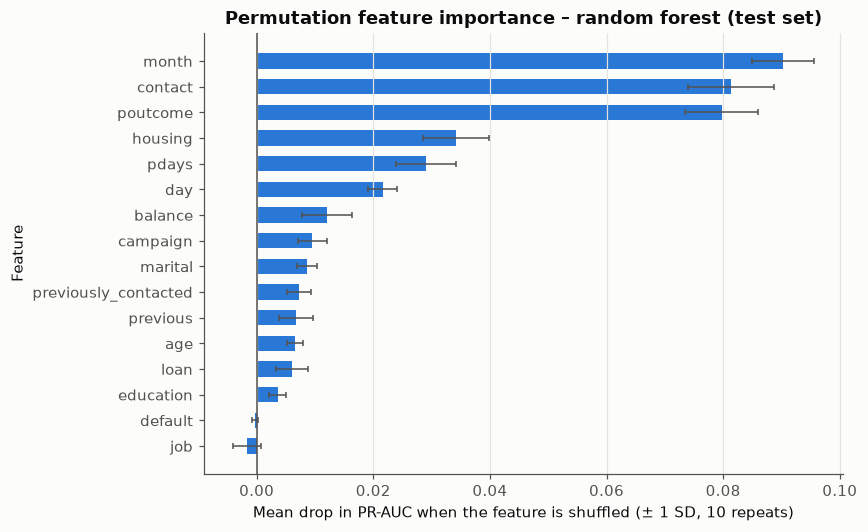

,feature,mean,std
0,month,0.0903,0.0053
1,contact,0.0813,0.0074
2,poutcome,0.0797,0.0062
3,housing,0.0342,0.0057
4,pdays,0.0291,0.0051
5,day,0.0216,0.0025
6,balance,0.0120,0.0043
7,campaign,0.0096,0.0025
8,marital,0.0086,0.0017
9,previously_contacted,0.0072,0.0021


In [17]:
start = time.perf_counter()
perm = permutation_importance(best_rf, X_test, y_test, scoring="average_precision",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=1)
print(f"Permutation importance computed in {time.perf_counter() - start:.0f}s")
imp = (pd.DataFrame({"feature": X_test.columns, "mean": perm.importances_mean, "std": perm.importances_std})
         .sort_values("mean", ascending=True))

fig, ax = plt.subplots(figsize=(7.5, 5.2))
ax.barh(imp["feature"], imp["mean"], xerr=imp["std"], color=MODEL_COLORS["Random forest"],
        height=0.6, error_kw={"ecolor": INK_MUTED, "elinewidth": 1, "capsize": 2})
ax.axvline(0, color=INK_MUTED, lw=1)
ax.set_title("Permutation feature importance – random forest (test set)")
ax.set_xlabel("Mean drop in PR-AUC when the feature is shuffled (± 1 SD, 10 repeats)")
ax.set_ylabel("Feature")
ax.grid(axis="y", visible=False)
save_fig(fig, "04_feature_importance")
plt.show()
imp.sort_values("mean", ascending=False).round(4).reset_index(drop=True)

### What drives the predictions

Three features dominate: `month` (mean drop in PR-AUC 0.090), `contact` (0.081) and `poutcome` (0.080). They are followed by `housing` (0.034), `pdays` (0.029) and `day` (0.022). Personal characteristics contribute very little: `age` (0.0065), `education` (0.0036), and `job` and `default` (about 0, within one standard deviation of zero). The model therefore relies mostly on *when and how* the bank called and on the outcome of earlier campaigns, not on who the client is. Because `month` and `day` encode calendar timing, the model is tied to the campaign schedule of 2008–2010, which the time-ordered check below tests. A near-zero score does not prove a feature is useless. When features are correlated (for example `job` = retired and `age`), shuffling one lets the model fall back on the other, so both can look unimportant.

### Overfitting check (bias–variance)

Comparing the forest's score on the data it was trained on with its cross-validated and test scores shows how much it memorises.

In [18]:
rf_train_pr_auc = average_precision_score(y_train, best_rf.predict_proba(X_train)[:, 1])
gap = pd.DataFrame({
    "PR-AUC": {
        "Training set (refit model)": rf_train_pr_auc,
        "5-fold CV (mean of held-out folds)": cv_summary["Random forest"]["pr_auc"][0],
        "Test set": results["Random forest (t = 0.50)"]["pr_auc"],
    }
})
gap.round(3)

,PR-AUC
Training set (refit model),0.718
5-fold CV (mean of held-out folds),0.441
Test set,0.454


The forest scores a PR-AUC of **0.718** on its own training data but only **0.441** in cross-validation and **0.454** on the test set. Fully grown trees (`max_depth=None`) partly memorise the training clients, which is high variance. Because the CV and test scores agree, the held-out estimate can still be trusted. The grid search shows the trade-off: the most regularised setting (`max_depth=12`, `min_samples_leaf=20`) cut the training score to 0.497 but also lowered CV PR-AUC to 0.431.

### Robustness check: time-ordered split

The rows of `bank-full.csv` are ordered by date (May 2008 to November 2010). A random split mixes every period into both training and test, so the model is always tested on months it has already seen. As a stricter check, the same tuned pipeline is refit on the **first 80% of rows in time** and tested on the **last 20%**.

In [19]:
cut = int(len(X) * 0.8)
X_early, X_late, y_early, y_late = X.iloc[:cut], X.iloc[cut:], y.iloc[:cut], y.iloc[cut:]
rf_time = clone(best_rf).fit(X_early, y_early)
late_proba = rf_time.predict_proba(X_late)[:, 1]
temporal = {
    "train_rows": int(len(X_early)), "test_rows": int(len(X_late)),
    "train_positive_rate": float(y_early.mean()), "test_positive_rate": float(y_late.mean()),
    "pr_auc": float(average_precision_score(y_late, late_proba)),
    "roc_auc": float(roc_auc_score(y_late, late_proba)),
}
pd.Series(temporal).to_frame("time-ordered split").round(4)

,time-ordered split
train_rows,36168.0000
test_rows,9043.0000
train_positive_rate,0.0673
test_positive_rate,0.3158
pr_auc,0.4704
roc_auc,0.6822


This check changes the picture. The subscription rate jumps from **6.7%** in the earliest 80% of rows to **31.6%** in the latest 20%, so later campaigns reached a very different mix of clients or ran under different conditions. ROC-AUC, which does not depend on the subscription rate, falls from 0.804 (random split) to **0.682**. PR-AUC (0.470) looks similar to before, but it must be compared with the new 0.316 prevalence: it is only about 1.5 times better than random, compared with about 3.9 times under the random split. The headline test scores are therefore optimistic for predicting *future* campaigns. This is the main limitation of the analysis.

### Bias check: performance by age group

Age is used as a model input, and older and younger clients may be treated differently by a call-prioritisation tool. The test set is split into age bands, and the tuned-threshold predictions are compared on each band's share of clients flagged, precision and recall. Equal recall across groups corresponds to the "equal opportunity" fairness criterion (Mehrabi et al., 2021).

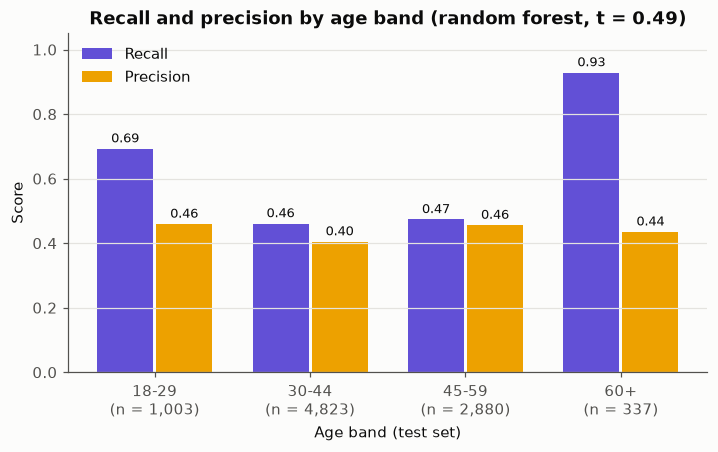

,age_band,n,actual_yes_rate,flagged_rate,precision,recall
0,18-29,1003,0.178,0.269,0.459,0.693
1,30-44,4823,0.100,0.114,0.405,0.461
2,45-59,2880,0.098,0.102,0.456,0.473
3,60+,337,0.332,0.709,0.435,0.929


In [20]:
AGE_BINS, AGE_LABELS = [0, 29, 44, 59, 120], ["18-29", "30-44", "45-59", "60+"]
age_band = pd.cut(X_test["age"], bins=AGE_BINS, labels=AGE_LABELS)


def group_metrics(y_true, y_pred, groups):
    """Return per-group size, actual and predicted positive rate, precision and recall."""
    rows = []
    for g in groups.cat.categories:
        m = (groups == g).to_numpy()
        rows.append({"age_band": g, "n": int(m.sum()), "actual_yes_rate": y_true[m].mean(),
                     "flagged_rate": y_pred[m].mean(),
                     "precision": precision_score(y_true[m], y_pred[m], zero_division=0),
                     "recall": recall_score(y_true[m], y_pred[m], zero_division=0)})
    return pd.DataFrame(rows)


subgroup = group_metrics(y_test.to_numpy(), rf_pred_tuned, age_band)

fig, ax = plt.subplots(figsize=(7.5, 4))
x = np.arange(len(AGE_LABELS))
w = 0.36
b1 = ax.bar(x - w / 2 - 0.01, subgroup["recall"], w, color="#6250d6", label="Recall")
b2 = ax.bar(x + w / 2 + 0.01, subgroup["precision"], w, color="#eda100", label="Precision")
for bars in (b1, b2):
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01, f"{bar.get_height():.2f}",
                ha="center", va="bottom", fontsize=8.5, color=INK)
ax.set_xticks(x, [f"{lab}\n(n = {n:,})" for lab, n in zip(AGE_LABELS, subgroup["n"])])
ax.set_ylim(0, 1.05)
ax.set_title(f"Recall and precision by age band (random forest, t = {THRESHOLD:.2f})")
ax.set_xlabel("Age band (test set)")
ax.set_ylabel("Score")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
save_fig(fig, "05_subgroup_age")
plt.show()
subgroup.round(3)

Precision is fairly even across age bands (0.405 to 0.459), but **recall is not**. Real subscribers aged 60+ are found 92.9% of the time and those aged 18–29 69.3% of the time, against only 46.1% (30–44) and 47.3% (45–59) for the middle bands. The model flags **70.9%** of clients aged 60+, whose actual subscription rate is 33.2%, compared with about 10–11% of clients aged 30–59. Part of this follows the real base rates, since older and younger clients subscribed more often in this data. Even so, it breaks equal opportunity: a subscriber in their 30s or 40s is about half as likely to be flagged as one over 60. The 60+ band also has only 337 test clients, so its numbers are less certain. In practice the tool would steer calls heavily towards older and retired clients, a group for whom high-pressure selling of financial products is an ethical concern. Proposed mitigation: before any deployment, track recall and the share flagged per age band at every retraining, and require a human suitability check plus a contact-frequency cap for flagged clients aged 60+.

### Save all final metrics

Everything the report quotes is written to `metrics.json`, so no number in the report is typed by hand.

In [21]:
def to_builtin(obj):
    """Recursively convert numpy / pandas scalars to plain Python types for JSON."""
    if isinstance(obj, dict):
        return {str(k): to_builtin(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_builtin(v) for v in obj]
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    return obj


key = {"Dummy (majority class)": "dummy", "Logistic regression": "logistic_regression",
       "Random forest (t = 0.50)": "random_forest_default", f"Random forest (tuned t = {THRESHOLD:.2f})": "random_forest_tuned"}
cm_t, cm_d = confusion_matrix(y_test, rf_pred_tuned), confusion_matrix(y_test, rf_pred_default)
metrics = {
    "dataset": {
        "name": "Bank Marketing (bank-full.csv)", "source": "UCI Machine Learning Repository",
        "url": "https://archive.ics.uci.edu/dataset/222/bank+marketing", "doi": "https://doi.org/10.24432/C5K306",
        "license": "CC BY 4.0", "n_rows": df.shape[0], "n_columns": df.shape[1], "n_input_features": df.shape[1] - 1,
        "n_positive": int(target_counts["yes"]), "n_negative": int(target_counts["no"]),
        "positive_rate": float(target_counts["yes"] / len(df)), "missing_values": int(missing.sum()),
        "duplicates": n_duplicates, "unknown_pct": unknown_pct.to_dict(), "pdays_never_contacted_pct": pdays_never_pct,
    },
    "preprocessing": {"dropped_columns": LEAKAGE_COLS, "engineered": ["previously_contacted"],
                      "n_numeric": len(num_cols), "n_categorical": len(cat_cols),
                      "n_model_features": len(num_cols) + len(cat_cols), "n_encoded_features": len(encoded_names)},
    "split": {"test_size": 0.2, "n_train": len(X_train), "n_test": len(X_test),
              "train_positive_rate": float(y_train.mean()), "test_positive_rate": float(y_test.mean())},
    "cv": {name: {m: {"mean": mu, "std": sd} for m, (mu, sd) in res.items()} for name, res in cv_summary.items()},
    "grid_search": {"best_params": {k.replace("model__", ""): v for k, v in grid.best_params_.items()},
                    "n_settings": len(grid.cv_results_["params"]), "n_folds": 5, "n_estimators": 300,
                    "results": cv_table.astype(object).where(cv_table.notna(), None).to_dict(orient="records")},
    "threshold": {"value": THRESHOLD, "oof_f1": float(f1_oof[best_t_idx]),
                  "oof_precision": float(prec_oof[best_t_idx]), "oof_recall": float(rec_oof[best_t_idx])},
    "test": {key[k]: v for k, v in results.items()},
    "confusion_matrix": {
        "random_forest_tuned": dict(zip(["tn", "fp", "fn", "tp"], cm_t.ravel().tolist())),
        "random_forest_default": dict(zip(["tn", "fp", "fn", "tp"], cm_d.ravel().tolist())),
    },
    "overfitting": {"train_pr_auc": rf_train_pr_auc, "cv_pr_auc": cv_summary["Random forest"]["pr_auc"][0],
                    "test_pr_auc": results["Random forest (t = 0.50)"]["pr_auc"]},
    "permutation_importance": imp.sort_values("mean", ascending=False).to_dict(orient="records"),
    "temporal_check": temporal,
    "subgroup_age": subgroup.to_dict(orient="records"),
    "environment": {"python": platform.python_version(), "sklearn": sklearn.__version__,
                    "pandas": pd.__version__, "numpy": np.__version__},
}
METRICS_PATH.write_text(json.dumps(to_builtin(metrics), indent=2), encoding="utf-8")
print(f"Saved {METRICS_PATH} ({METRICS_PATH.stat().st_size:,} bytes)")
print("Figures:", sorted(p.name for p in FIG_DIR.glob("*.png")))

Saved metrics.json (9,000 bytes)
Figures: ['01_class_balance.png', '02_confusion_matrix.png', '03_roc_pr_curves.png', '04_feature_importance.png', '05_subgroup_age.png']


## Sources Cited in This Notebook

- Mehrabi, N., Morstatter, F., Saxena, N., Lerman, K., & Galstyan, A. (2021). A survey on bias and fairness in machine learning. *ACM Computing Surveys, 54*(6), 1–35. https://doi.org/10.1145/3457607
- Moro, S., Rita, P., & Cortez, P. (2014). *Bank marketing* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5K306
- Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE, 10*(3), Article e0118432. https://doi.org/10.1371/journal.pone.0118432
- scikit-learn developers. (2026). *User guide* (Version 1.9.1). scikit-learn. https://scikit-learn.org/1.9/user_guide.html

The `Pipeline` + `ColumnTransformer` structure and the permutation-importance call follow patterns shown in the scikit-learn user guide, adapted to this dataset.

## 6. Notebook Summary

This project predicts, before any call is made, whether a client of a Portuguese bank will subscribe to a term deposit, a supervised binary classification task on the UCI Bank Marketing data (45,211 clients, 11.7% subscribers) with the leaking `duration` column removed. A class-weighted random forest, tuned with 5-fold cross-validation on PR-AUC, was chosen as the main model and compared against a majority-class dummy and a class-weighted logistic regression. On the held-out test set the forest reached a PR-AUC of 0.454 (logistic regression 0.409, dummy 0.117) and a ROC-AUC of 0.804, and at the 0.49 threshold chosen on training data it had a precision of 0.432 and a recall of 0.553, so about 43 of every 100 flagged clients subscribe compared with about 12 under random calling. The main challenges were class imbalance, which made the dummy's 88.3% accuracy meaningless, and overfitting, with a training PR-AUC of 0.718. A time-ordered split lowered ROC-AUC to 0.682, and recall ranged from 0.46 for clients aged 30–44 to 0.93 for clients aged 60+, so the model would need revalidation on recent campaigns and per-age-group monitoring before any real use.